# Semaine 4 : courbes de remplissage randomisées, modèle OLS, prévision ARIMA

Objectifs du cours (27 octobre) :
1. build randomized capacity utilization curves
2. build OLS-based demand model f(price, competitor_price) = demand
3. price optimization based on the estimated demand model
4. price prediction using time series analysis
5. price optimization based on the predicted competitor's price

Données : tous nos résultats DPC disponibles (CSV de la semaine 2 + runs du 21/10 et du 24/10), soit 16 compétitions.

In [1]:
import glob, os, time, pickle, warnings, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
pd.options.mode.chained_assignment = None
plt.style.use('ggplot')

files = ['../duopoly_competition_details1.csv'] + sorted(glob.glob('../résultat_DPC/*.csv'))
frames = []
for f in files:
    name = os.path.basename(f)
    run = 'avant 16/10' if name == 'duopoly_competition_details1.csv' else name.split('details')[-1][:-4]
    frames.append(pd.read_csv(f).assign(run=run))
df = pd.concat(frames, ignore_index=True)
df['errors'] = df['errors'].fillna('')
df['revenue'] = df['price'] * df['demand']
df['key'] = df['competition_id'] + '_' + df['selling_season'].astype(str)
df.groupby('run').agg(competitions=('competition_id', 'nunique'), saisons=('key', 'nunique'),
                      revenu_moyen_saison=('revenue', lambda r: r.sum() / df.loc[r.index, 'key'].nunique()))

,competitions,saisons,revenu_moyen_saison
run,,,
10_21_2026,6,600,1491.055500
10_24_2026,6,600,587.623833
avant 16/10,4,400,1740.731250


# 1. Courbes de remplissage randomisées (capacity utilization curves)

Méthode de la semaine 2 : la courbe cible est la moyenne des ventes cumulées des 20 % de saisons qui ont rapporté le plus.

Nouveauté de la semaine 4 : les ventes sont aléatoires (arrivées de Poisson). Une seule courbe fait réagir le prix au moindre écart, même quand il vient du hasard.
On ajoute donc des **marges** (fluctuations stochastiques) autour de la cible :
- marge basse = quantile 25 % des courbes des meilleures saisons ;
- marge haute = quantile 75 %.

Entre les deux marges, on considère que l'écart vient du hasard et on garde le prix ; on ne corrige qu'en dehors.

In [2]:
season_revenue = df.groupby('key')['revenue'].sum()
top_seasons = season_revenue[season_revenue >= season_revenue.quantile(0.8)].index
print('saisons du top 20 % par run :', df[df.key.isin(top_seasons)].groupby('run').key.nunique().to_dict())

# ventes cumulées (sièges) par période, une colonne par saison
cum_sales = df.pivot_table(values='demand', index='selling_period', columns='key', aggfunc='sum').cumsum()
top_curves = cum_sales[top_seasons]

capacity_band = pd.DataFrame({
    'lower': top_curves.quantile(0.25, axis=1),
    'target': top_curves.mean(axis=1),
    'upper': top_curves.quantile(0.75, axis=1),
})
# comparaison : marge théorique d'une loi de Poisson (écart-type = racine de la moyenne)
capacity_band['poisson_lower'] = capacity_band['target'] - np.sqrt(capacity_band['target'])
capacity_band['poisson_upper'] = capacity_band['target'] + np.sqrt(capacity_band['target'])
capacity_band.iloc[[0, 9, 24, 49, 74, 89, 99]].round(1).T

saisons du top 20 % par run : {'10_21_2026': 142, '10_24_2026': 17, 'avant 16/10': 161}


selling_period,1,10,25,50,75,90,100
lower,0.0,5.0,14.0,31.0,55.0,70.0,77.0
target,0.1,6.8,19.2,41.4,61.0,72.7,78.1
upper,0.0,9.0,24.0,52.0,68.0,76.0,80.0
poisson_lower,-0.2,4.2,14.8,34.9,53.2,64.2,69.3
poisson_upper,0.5,9.4,23.6,47.8,68.8,81.2,87.0


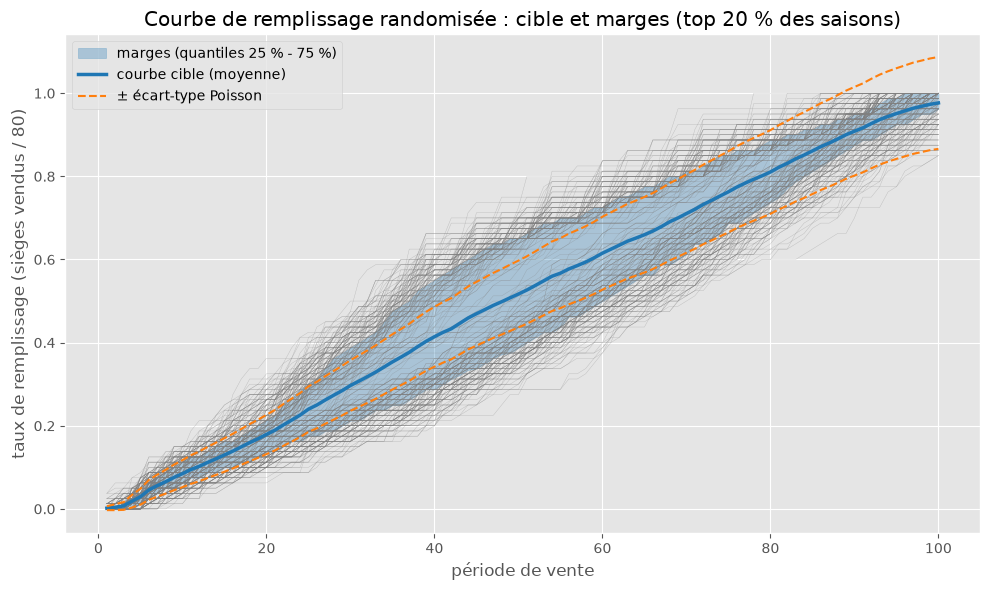

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(top_curves.index, top_curves.values / 80, color='grey', linewidth=0.3, alpha=0.4)
ax.fill_between(capacity_band.index, capacity_band['lower'] / 80, capacity_band['upper'] / 80,
                color='tab:blue', alpha=0.3, label='marges (quantiles 25 % - 75 %)')
ax.plot(capacity_band.index, capacity_band['target'] / 80, color='tab:blue', linewidth=2.5, label='courbe cible (moyenne)')
ax.plot(capacity_band.index, capacity_band['poisson_lower'] / 80, color='tab:orange', linestyle='--', label='± écart-type Poisson')
ax.plot(capacity_band.index, capacity_band['poisson_upper'] / 80, color='tab:orange', linestyle='--')
ax.set_xlabel('période de vente')
ax.set_ylabel('taux de remplissage (sièges vendus / 80)')
ax.set_title('Courbe de remplissage randomisée : cible et marges (top 20 % des saisons)')
ax.legend(loc='upper left')
fig.tight_layout()
plt.show()

### 1b. Méthode du cours : courbes cibles tirées au hasard (`W4_FULL_dynamic_utilization_curves`)
- on calcule l'augmentation de la courbe cible tous les 5 jours ;
- on ajuste une loi normale (μ, σ) sur ces augmentations ;
- on tire 20 pas au hasard dans cette loi et on les additionne : on obtient une nouvelle courbe cible, différente à chaque saison.

Intérêt : la cible change d'une saison à l'autre, donc notre prix varie davantage, ce qui donne au modèle OLS des données plus riches pour mesurer l'effet du prix.

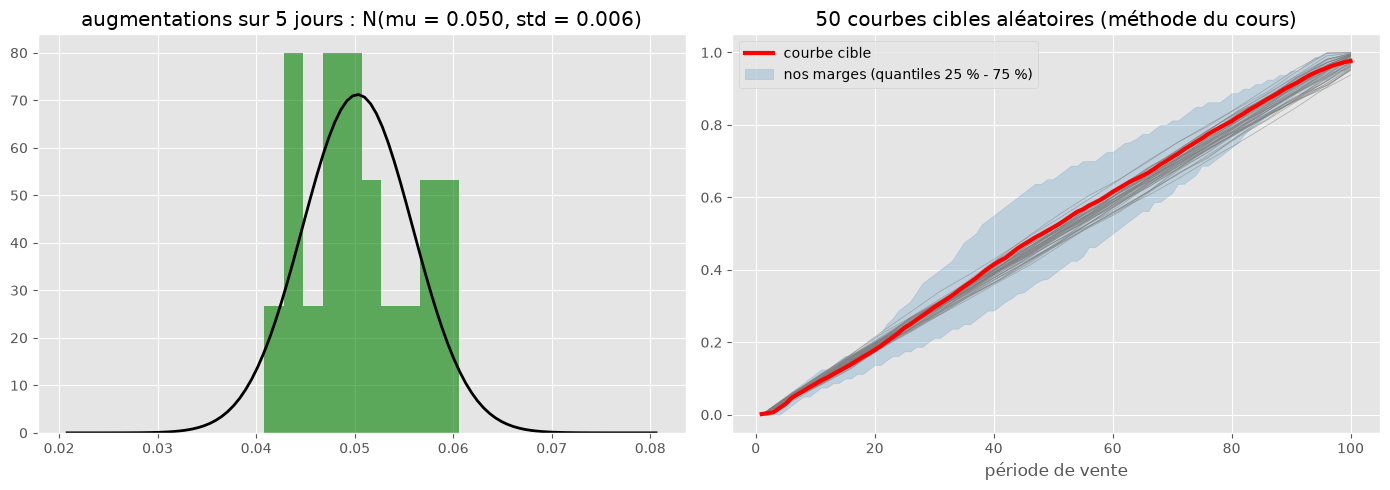

écart-type des courbes aléatoires au jour 50 : 1.4 sièges, au jour 100 : 1.1 sièges


In [4]:
from scipy.stats import norm

target_5d = capacity_band.loc[np.arange(1, 101, 5), 'target'] / 80
delta_values = target_5d.diff().dropna().values
mu, std = norm.fit(delta_values)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(delta_values, density=True, alpha=0.6, color='g')
x = np.linspace(delta_values.min() - 0.02, delta_values.max() + 0.02, 100)
axes[0].plot(x, norm.pdf(x, mu, std), 'k', linewidth=2)
axes[0].set_title('augmentations sur 5 jours : N(mu = %.3f, std = %.3f)' % (mu, std))

rng = np.random.default_rng(0)
days = np.arange(1, 102, 5)
random_curves = []
for i in range(200):
    steps = np.clip(rng.normal(mu, std, size=20), 0, None)
    curve = np.minimum(np.concatenate([[0], np.cumsum(steps)]), 1.0)
    random_curves.append(np.interp(np.arange(1, 101), days, curve))
random_curves = np.array(random_curves)
for c in random_curves[:50]:
    axes[1].plot(np.arange(1, 101), c, color='grey', linewidth=0.5, alpha=0.6)
axes[1].plot(capacity_band.index, capacity_band['target'] / 80, color='r', linewidth=3, label='courbe cible')
axes[1].fill_between(capacity_band.index, capacity_band['lower'] / 80, capacity_band['upper'] / 80,
                     color='tab:blue', alpha=0.2, label='nos marges (quantiles 25 % - 75 %)')
axes[1].set_title('50 courbes cibles aléatoires (méthode du cours)')
axes[1].set_xlabel('période de vente')
axes[1].legend(loc='upper left')
fig.tight_layout()
plt.show()
print('écart-type des courbes aléatoires au jour 50 : %.1f sièges, au jour 100 : %.1f sièges'
      % (random_curves[:, 49].std() * 80, random_curves[:, 99].std() * 80))

### Courbes cibles vs courbes de ventes réelles (thème de la présentation #1)
Les courbes de ventes (booking curves) de la version soumise le 20/10, pendant les runs du 21/10 et du 24/10, comparées aux marges de la courbe cible.

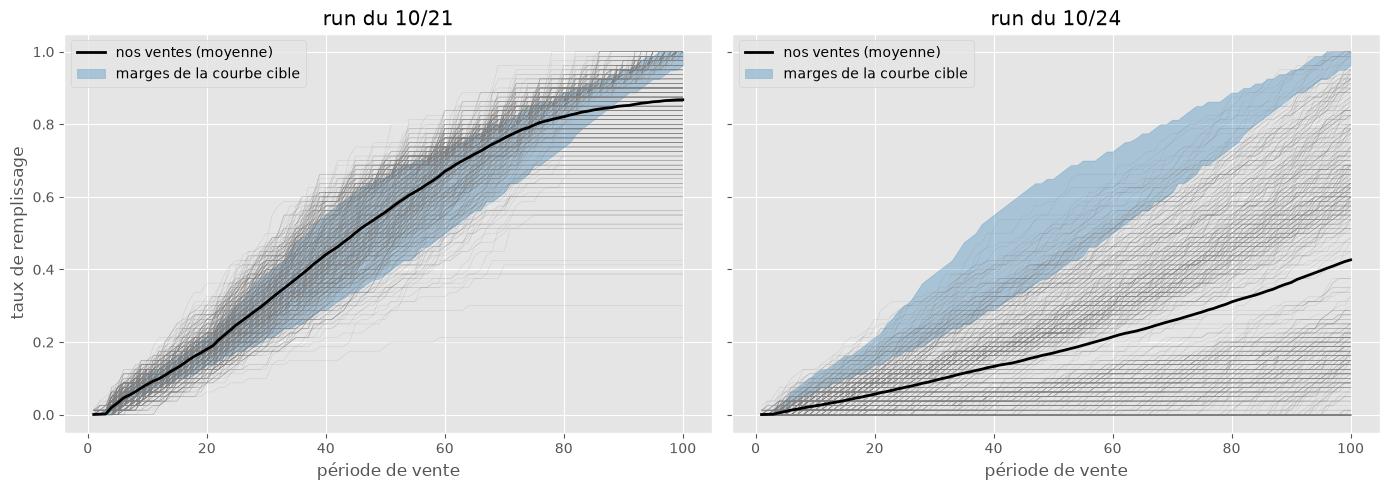

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, run in zip(axes, ['10_21_2026', '10_24_2026']):
    keys = df[df.run == run].key.unique()
    ax.plot(cum_sales.index, cum_sales[keys].values / 80, color='grey', linewidth=0.3, alpha=0.3)
    ax.plot(cum_sales.index, cum_sales[keys].mean(axis=1) / 80, color='black', linewidth=2, label='nos ventes (moyenne)')
    ax.fill_between(capacity_band.index, capacity_band['lower'] / 80, capacity_band['upper'] / 80,
                    color='tab:blue', alpha=0.3, label='marges de la courbe cible')
    ax.set_title('run du ' + run[:5].replace('_', '/'))
    ax.set_xlabel('période de vente')
    ax.legend(loc='upper left')
axes[0].set_ylabel('taux de remplissage')
fig.tight_layout()
plt.show()

# 2. Modèle de demande OLS sur toutes les compétitions

En semaine 3, `OLS_MODELS` venait d'une seule compétition (`3HmCSH`), ce qui donnait des prix trop bas ailleurs.
On applique la tâche (2) du notebook W3 à toutes les compétitions : un modèle par tranche de 20 jours, estimé sur l'ensemble des 16 compétitions.
- entraînement : saisons 1 à 50 ; test : saisons 51 à 100 (découpage dans le temps) ;
- on retire les périodes où le concurrent est en rupture : la demande n'y dépend plus de son prix.

In [6]:
OLD_OLS_MODELS = {
    20: {'price': -0.0299, 'price_competitor': 0.0115, 'intercept': 0.9819},
    40: {'price': -0.0604, 'price_competitor': 0.0467, 'intercept': 0.8657},
    60: {'price': -0.1449, 'price_competitor': 0.1353, 'intercept': 0.9659},
    80: {'price': -0.0971, 'price_competitor': 0.0907, 'intercept': 1.0316},
    100: {'price': -0.0794, 'price_competitor': 0.0588, 'intercept': 1.1548},
}
def predict(m, d):
    return m['intercept'] + m['price'] * d['price'] + m['price_competitor'] * d['price_competitor']

duo = df[df.competitor_has_capacity]
ols_models, rows = {}, []
for p_max in range(20, 101, 20):
    tranche = duo[(duo.selling_period > p_max - 20) & (duo.selling_period <= p_max)]
    train, test = tranche[tranche.selling_season <= 50], tranche[tranche.selling_season > 50]
    X = train[['price', 'price_competitor']]
    X['intercept'] = 1
    res = sm.OLS(train['demand'], X).fit()
    ols_models[p_max] = res.params.to_dict()
    rows.append({'tranche': f'{p_max - 19}-{p_max}', **res.params.round(4).to_dict(), 'R2': round(res.rsquared, 3),
                 'MAE test nouveau': (predict(ols_models[p_max], test) - test.demand).abs().mean(),
                 'MAE test ancien (W3)': (predict(OLD_OLS_MODELS[p_max], test) - test.demand).abs().mean()})
pd.DataFrame(rows).round(3)

,tranche,price,price_competitor,intercept,R2,MAE test nouveau,MAE test ancien (W3)
0,1-20,-0.012,0.006,0.635,0.060,0.599,0.667
1,21-40,-0.006,0.005,0.666,0.009,0.733,0.833
2,41-60,-0.011,0.012,0.670,0.042,0.722,1.507
3,61-80,-0.014,0.013,0.756,0.074,0.716,1.303
4,81-100,-0.011,0.008,0.737,0.068,0.707,1.141


In [7]:
def optimal_price(m, comp_price, lo=15, hi=150):
    a = m['intercept'] + m['price_competitor'] * comp_price
    return np.clip(-a / (2 * m['price']), lo, hi) if m['price'] < 0 and a > 0 else np.nan

comp_prices = [10, 20, 35, 50, 80, 150]
table = {f'nouveau, conc={pc}': [optimal_price(ols_models[k], pc) for k in ols_models] for pc in comp_prices}
table.update({f'ancien, conc={pc}': [optimal_price(OLD_OLS_MODELS[k], pc) for k in ols_models] for pc in (20, 50)})
pd.DataFrame(table, index=[f'{k - 19}-{k}' for k in ols_models]).round(1)

,"nouveau, conc=10","nouveau, conc=20","nouveau, conc=35","nouveau, conc=50","nouveau, conc=80","nouveau, conc=150","ancien, conc=20","ancien, conc=50"
1-20,30.1,32.7,36.5,40.4,48.0,66.0,20.3,26.0
21-40,54.8,58.6,64.2,69.9,81.2,107.6,15.0,26.5
41-60,35.2,40.8,49.1,57.4,74.0,112.7,15.0,26.7
61-80,31.7,36.4,43.4,50.4,64.4,97.2,15.0,28.7
81-100,35.8,39.2,44.5,49.7,60.1,84.4,15.0,25.8


### Sauvegarde des paramètres pour `duopoly.py`
Le cours 4 montre comment déposer des fichiers supplémentaires (`.pkl`) sur la plateforme et les lire depuis `/root/partcipant_folder/`.
`duopoly.py` lit `duopoly_params.pkl` et garde les valeurs de la semaine 3 si le fichier est absent.

In [8]:
params = {
    'ols_models': ols_models,
    'capacity_band': {int(t): {k: float(capacity_band.loc[t, k]) for k in ('lower', 'target', 'upper')}
                      for t in capacity_band.index},
    'curve_steps': {'mu': float(mu), 'std': float(std)},
    'source': [f.split('/')[-1] for f in files],
}
with open('../duopoly_params.pkl', 'wb') as f:
    pickle.dump(params, f)
print('../duopoly_params.pkl enregistré :', list(params))

../duopoly_params.pkl enregistré : ['ols_models', 'capacity_band', 'curve_steps', 'source']


# 3. Prévision du prix concurrent par séries temporelles (ARIMA)

ARIMA(p, d, q) prédit la suite d'une série à partir de ses valeurs passées (AR), de ses différences (I) et de ses erreurs passées (MA).
Ici la série est le prix du concurrent pendant la saison. On suit le tutoriel statsmodels : ARIMA(1,1,1), découpage dans le temps.

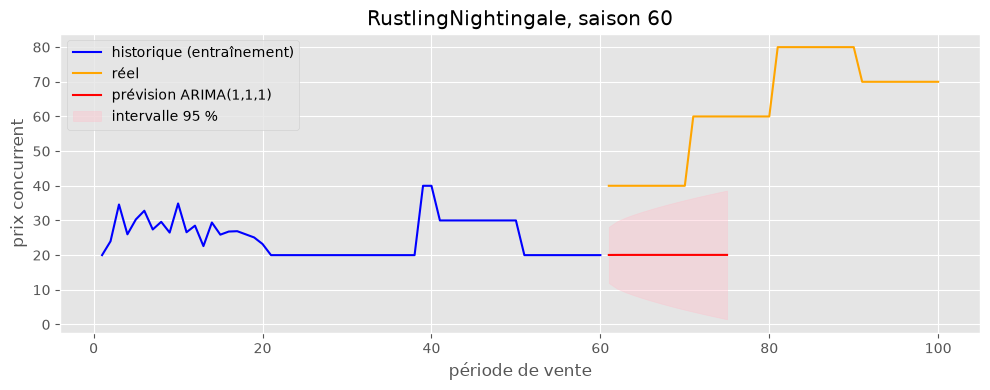

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2865      0.413      0.694      0.488      -0.523       1.096
ma.L1         -0.6171      0.371     -1.662      0.097      -1.345       0.111
sigma2        17.0688      1.382     12.354      0.000      14.361      19.777


In [9]:
example = df[(df.competition_id == '498Xgm') & (df.selling_season == 60)].sort_values('selling_period')
y = example['price_competitor'].values
t_cut = 60
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    fit = ARIMA(y[:t_cut], order=(1, 1, 1)).fit()
fc = fit.get_forecast(steps=15)
ci = fc.conf_int()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, t_cut + 1), y[:t_cut], color='blue', label='historique (entraînement)')
ax.plot(range(t_cut + 1, 101), y[t_cut:], color='orange', label='réel')
ax.plot(range(t_cut + 1, t_cut + 16), fc.predicted_mean, color='red', label='prévision ARIMA(1,1,1)')
ax.fill_between(range(t_cut + 1, t_cut + 16), ci[:, 0], ci[:, 1], color='pink', alpha=0.4, label='intervalle 95 %')
ax.set_xlabel('période de vente')
ax.set_ylabel('prix concurrent')
ax.set_title('RustlingNightingale, saison 60')
ax.legend(loc='upper left')
fig.tight_layout()
plt.show()
print(fit.summary().tables[1])

### Évaluation : ARIMA vs « le concurrent garde son prix d'hier »
Prévision à un pas (le prix du lendemain), sur 2 saisons de test par compétition, tous les 5 jours.

In [10]:
rows, times = [], []
for comp, dc in df.groupby('competition_id'):
    for season in (55, 80):
        y = dc[dc.selling_season == season].sort_values('selling_period')['price_competitor'].values
        for t in range(15, 100, 5):
            t0 = time.perf_counter()
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')
                    fc = ARIMA(y[:t], order=(1, 1, 1)).fit().forecast(1)[0]
            except Exception:
                fc = y[t - 1]
            times.append(time.perf_counter() - t0)
            rows.append({'concurrent': dc.competitor_id.iloc[0], 'erreur_prix_hier': abs(y[t - 1] - y[t]),
                         'erreur_arima': abs(fc - y[t]), 'prix_change': y[t - 1] != y[t]})
arima_eval = pd.DataFrame(rows)
print('temps par ajustement ARIMA : moyenne %.0f ms, max %.0f ms' % (1000 * np.mean(times), 1000 * np.max(times)))
print('erreur moyenne : prix d\'hier %.2f, ARIMA %.2f' % (arima_eval.erreur_prix_hier.mean(), arima_eval.erreur_arima.mean()))
arima_eval.groupby('concurrent').mean().round(2)

temps par ajustement ARIMA : moyenne 18 ms, max 74 ms
erreur moyenne : prix d'hier 2.47, ARIMA 2.50


,erreur_prix_hier,erreur_arima,prix_change
concurrent,,,
AttentiveOriole,0.00,0.00,0.00
DelicateMoose,2.03,2.15,0.53
ElectricButterfly,0.50,0.54,0.19
FlashyInchworm,4.37,4.99,0.44
IndependentPorpoise,3.68,3.74,0.53
RustlingNightingale,8.89,8.32,0.91
SaffronDolphin,0.00,0.00,0.00
Winner_2023,0.26,0.26,0.15


# 4. Simulation : est-ce que la semaine 4 améliore l'algorithme ?

Même principe que la partie 3 du notebook de simulation W2, étendu aux 16 compétitions :
- chaque compétition est un « monde » avec son propre modèle de demande OLS (estimé sur toutes ses saisons) ;
- prix concurrent et rupture du concurrent rejoués depuis le CSV (saisons 51 à 100) ;
- notre demande ~ Poisson(modèle), plafonnée à 80 sièges ;
- **concurrent en rupture** : ses clients n'ont plus que nous ; on simule cela avec un prix concurrent de 150 (prix maximum accepté par les clients) ;
- le cours dit que la demande baisse avec le prix : si l'estimation donne une pente ≥ 0 (données où notre prix variait peu), on la fixe à -0,005.

⚠️ Limites : le concurrent ne réagit pas à nos prix, et les mondes viennent des mêmes compétitions que le modèle OLS (saisons 1-50), donc le test reste optimiste.

In [11]:
def load_algo(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

true_models = {}
for comp, dc in duo.groupby('competition_id'):
    true_models[comp] = {}
    for p_max in range(20, 101, 20):
        d = dc[(dc.selling_period > p_max - 20) & (dc.selling_period <= p_max)]
        if len(d) < 100:
            # concurrent presque toujours en rupture sur cette tranche : on reprend le modèle commun
            m = dict(ols_models[p_max])
        else:
            X = d[['price', 'price_competitor']]
            X['intercept'] = 1
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                m = sm.OLS(d['demand'], X).fit().params.to_dict()
        m['price'] = min(m['price'], -0.005)
        true_models[comp][p_max] = m

def simulate_season(algo, df_season, model, rng, capacity=80):
    np.random.seed(int(rng.integers(1e9)))   # tirage de la courbe aléatoire reproductible
    df_season = df_season.sort_values('selling_period')
    comp_prices = df_season['price_competitor'].values
    comp_capacity = df_season['competitor_has_capacity'].values.astype(bool)
    info, my_prices, my_demand, sold = None, [], [], 0
    for t in range(1, 101):
        ph = None if t == 1 else np.array([my_prices, comp_prices[:t - 1]])
        dh = None if t == 1 else np.array(my_demand)
        price, info = algo.p(1, t, ph, dh, bool(comp_capacity[t - 1]), info)
        m = model[next(k for k in (20, 40, 60, 80, 100) if t <= k)]
        pc = comp_prices[t - 1] if comp_capacity[t - 1] else 150.0
        lam = max(0.0, m['intercept'] + m['price'] * price + m['price_competitor'] * pc)
        q = min(int(rng.poisson(lam)), capacity - sold)
        sold += q
        my_prices.append(price)
        my_demand.append(q)
    return np.dot(my_prices, my_demand), sold, np.mean(my_prices)

def evaluate(algo, seasons=range(51, 101), n_seeds=2):
    rows = []
    for comp, dc in df.groupby('competition_id'):
        for season in seasons:
            ds = dc[dc.selling_season == season]
            for seed in range(n_seeds):
                rev, sold, mean_price = simulate_season(algo, ds, true_models[comp],
                                                        np.random.default_rng(1000 * seed + season))
                rows.append({'competition_id': comp, 'run': dc.run.iloc[0], 'revenue': rev, 'sold': sold,
                             'mean_price': mean_price})
    return pd.DataFrame(rows)

def price_variety(results):
    # écart-type, d'une saison à l'autre, du prix moyen de la saison (variété des prix observés)
    return pd.Series({name: r.groupby('competition_id').mean_price.std().mean() for name, r in results.items()}).round(1)

def summary(results):
    out = pd.DataFrame({name: r.groupby('run').revenue.mean() for name, r in results.items()})
    out.loc['MOYENNE'] = [r.revenue.mean() for r in results.values()]
    return out.round(0)

### Comparaison des versions (sans ARIMA, plus rapide)
- **W3 soumise** : version du 20/10 (`archive/week-3-submitted/`)
- **W4** : marges + OLS commun + nouveau mode monopole
- W4 sans marges / W4 avec l'ancien mode monopole : pour voir l'effet de chaque changement
- W4 courbe aléatoire (cours) : nouvelle courbe cible tirée au hasard à chaque saison, sans marges
- W4 courbe aléatoire + marges : les deux idées combinées

In [12]:
algo_w3 = load_algo('algo_w3', '../archive/week-3-submitted/duopoly_2026-10-20.py')
def algo_w4(name, **settings):
    a = load_algo(name, '../duopoly.py')
    a.USE_ARIMA = False
    for k, v in settings.items():
        setattr(a, k, v)
    return a

results = {
    'W3 soumise': evaluate(algo_w3),
    'W4': evaluate(algo_w4('w4')),
    'W4 sans marges': evaluate(algo_w4('w4_nb', USE_CAPACITY_BAND=False)),
    'W4 ancien monopole': evaluate(algo_w4('w4_om', MONOPOLY_USE_MODEL=False)),
    'W4 courbe aléatoire (cours)': evaluate(algo_w4('w4_rc', RANDOM_TARGET_CURVE=True, USE_CAPACITY_BAND=False)),
    'W4 courbe aléatoire + marges': evaluate(algo_w4('w4_rcb', RANDOM_TARGET_CURVE=True)),
}
print('variété des prix (écart-type du prix moyen entre saisons) :')
print(price_variety(results).to_string())
summary(results)

variété des prix (écart-type du prix moyen entre saisons) :
W3 soumise                      6.1
W4                              4.7
W4 sans marges                  4.8
W4 ancien monopole              5.3
W4 courbe aléatoire (cours)     4.8
W4 courbe aléatoire + marges    4.7


,W3 soumise,W4,W4 sans marges,W4 ancien monopole,W4 courbe aléatoire (cours),W4 courbe aléatoire + marges
run,,,,,,
10_21_2026,2628.0,3466.0,3404.0,3170.0,3436.0,3464.0
10_24_2026,599.0,619.0,598.0,680.0,600.0,618.0
avant 16/10,1967.0,2258.0,2265.0,2179.0,2242.0,2199.0
MOYENNE,1702.0,2096.0,2067.0,1989.0,2074.0,2080.0


### Effet d'ARIMA (sous-échantillon : 5 saisons par compétition, ARIMA est plus lent)

In [13]:
seasons_small = [55, 65, 75, 85, 95]
t0 = time.perf_counter()
res_arima = {
    "W4 prix d'hier": evaluate(algo_w4('w4_s'), seasons_small, n_seeds=1),
    'W4 + ARIMA': evaluate(algo_w4('w4_a', USE_ARIMA=True), seasons_small, n_seeds=1),
}
print('durée %.0f s' % (time.perf_counter() - t0))
diff = res_arima['W4 + ARIMA'].revenue.values - res_arima["W4 prix d'hier"].revenue.values
print('écart de revenu par saison (ARIMA - prix d\'hier) : moyenne %.1f, saisons différentes : %d / %d'
      % (diff.mean(), (np.abs(diff) > 0.01).sum(), len(diff)))
summary(res_arima)

durée 44 s
écart de revenu par saison (ARIMA - prix d'hier) : moyenne 3.9, saisons différentes : 44 / 80


,W4 prix d'hier,W4 + ARIMA
run,,
10_21_2026,3575.0,3584.0
10_24_2026,620.0,621.0
avant 16/10,2234.0,2234.0
MOYENNE,2132.0,2135.0


### Vérification rapide du plancher et du poids OLS (réglés en semaine 3 sur une seule compétition)

In [14]:
rows = []
for floor in (15, 25, 30):
    for w in (0.5, 1.0):
        r = evaluate(algo_w4(f'w4_{floor}_{w}', MIN_PRICE=float(floor), OLS_WEIGHT=w), n_seeds=1)
        rows.append({'plancher': floor, 'OLS_WEIGHT': w, 'revenu': round(r.revenue.mean()),
                     **r.groupby('run').revenue.mean().round().to_dict()})
pd.DataFrame(rows)

,plancher,OLS_WEIGHT,revenu,10_21_2026,10_24_2026,avant 16/10
0,15,0.5,2005,3393.0,594.0,2040.0
1,15,1.0,2096,3471.0,612.0,2262.0
2,25,0.5,1990,3427.0,526.0,2030.0
3,25,1.0,2071,3490.0,543.0,2236.0
4,30,0.5,1984,3409.0,537.0,2016.0
5,30,1.0,2062,3486.0,547.0,2199.0
